<a href="https://colab.research.google.com/github/iagocomin/DataScience_Project1/blob/main/Predicting_Student_Health_Risk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🩺 Predicting Student Health Risk

## 📌 Sobre o projeto

Este projeto tem como objetivo prever o risco de saúde de estudantes utilizando técnicas de Machine Learning. A classificação é realizada a partir de informações relacionadas aos hábitos de vida, características físicas e indicadores de saúde dos estudantes.

---

## 📊 Dataset

Os dados utilizados foram obtidos no **Kaggle** e contêm informações sobre diferentes aspectos da saúde e do estilo de vida dos estudantes.

(https://www.kaggle.com/competitions/playground-series-s6e7/data)

As principais variáveis utilizadas foram:

- **Health Condition** (variável-alvo);
- **Sleep Duration**;
- **Heart Rate**;
- **BMI**;
- **Calorie Expenditure**;
- **Step Count**;
- **Exercise Duration**;
- **Water Intake**;
- **Diet Type**;
- **Stress Level**;
- **Sleep Quality**;
- **Physical Activity Level**;
- **Smoking/Alcohol**;
- **Gender**.

In [40]:
import random
random.seed(42)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')


train = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Predicting Student Health Risk/train.csv', header=(0))
test = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Predicting Student Health Risk/test.csv', header=(0))

print("Número de linhas e colunas no conjunto de treinamento:", train.shape)
print("Número de linhas e colunas no conjunto de teste:", test.shape)
attributes = list(train.columns)
train.head(10)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Número de linhas e colunas no conjunto de treinamento: (690088, 15)
Número de linhas e colunas no conjunto de teste: (295753, 14)


,id,health_condition,sleep_duration,heart_rate,bmi,calorie_expenditure,step_count,exercise_duration,water_intake,diet_type,stress_level,sleep_quality,physical_activity_level,smoking_alcohol,gender
0,0,unhealthy,5.22,70.6,25.66,2174.0,1326.0,19.8,1.86,veg,high,average,sedentary,yes,female
1,1,at-risk,5.53,71.3,25.84,1966.0,9891.0,49.9,1.26,non-veg,low,average,moderate,yes,other
2,2,unhealthy,5.29,75.4,24.54,2688.0,14216.0,38.1,1.60,veg,high,poor,active,yes,male
3,3,unhealthy,4.70,77.2,23.13,2630.0,7174.0,59.9,2.02,veg,high,average,active,occasional,female
4,4,at-risk,7.23,73.4,28.44,2560.0,6584.0,46.0,2.25,veg,NaN,average,sedentary,NaN,male
5,5,at-risk,5.11,82.8,24.43,2290.0,2134.0,29.2,2.02,veg,low,poor,sedentary,occasional,male
6,6,at-risk,8.21,71.1,24.14,2723.0,12984.0,54.5,2.01,balanced,low,NaN,moderate,no,female
7,7,at-risk,7.47,87.0,23.51,NaN,3096.0,37.5,0.51,balanced,low,average,sedentary,occasional,male
8,8,unhealthy,5.94,75.4,24.36,NaN,12165.0,61.6,1.56,veg,high,average,active,no,other
9,9,at-risk,6.97,80.1,20.47,2928.0,13108.0,51.9,2.53,veg,medium,good,active,no,male


Removemos a coluna id dos conjuntos de treinamento e de teste, pois essa variável não apresenta relevância para o modelo neste momento.

In [41]:
train.drop(['id'],axis = 1, inplace = True)
train.head(10)

,health_condition,sleep_duration,heart_rate,bmi,calorie_expenditure,step_count,exercise_duration,water_intake,diet_type,stress_level,sleep_quality,physical_activity_level,smoking_alcohol,gender
0,unhealthy,5.22,70.6,25.66,2174.0,1326.0,19.8,1.86,veg,high,average,sedentary,yes,female
1,at-risk,5.53,71.3,25.84,1966.0,9891.0,49.9,1.26,non-veg,low,average,moderate,yes,other
2,unhealthy,5.29,75.4,24.54,2688.0,14216.0,38.1,1.60,veg,high,poor,active,yes,male
3,unhealthy,4.70,77.2,23.13,2630.0,7174.0,59.9,2.02,veg,high,average,active,occasional,female
4,at-risk,7.23,73.4,28.44,2560.0,6584.0,46.0,2.25,veg,NaN,average,sedentary,NaN,male
5,at-risk,5.11,82.8,24.43,2290.0,2134.0,29.2,2.02,veg,low,poor,sedentary,occasional,male
6,at-risk,8.21,71.1,24.14,2723.0,12984.0,54.5,2.01,balanced,low,NaN,moderate,no,female
7,at-risk,7.47,87.0,23.51,NaN,3096.0,37.5,0.51,balanced,low,average,sedentary,occasional,male
8,unhealthy,5.94,75.4,24.36,NaN,12165.0,61.6,1.56,veg,high,average,active,no,other
9,at-risk,6.97,80.1,20.47,2928.0,13108.0,51.9,2.53,veg,medium,good,active,no,male


In [42]:
Id_test = test['id']
test.drop(['id'],axis = 1, inplace = True)
test.head(10)

,sleep_duration,heart_rate,bmi,calorie_expenditure,step_count,exercise_duration,water_intake,diet_type,stress_level,sleep_quality,physical_activity_level,smoking_alcohol,gender
0,5.35,64.9,23.48,2745.0,14167.0,59.5,1.86,veg,high,poor,active,occasional,male
1,NaN,83.1,22.42,1773.0,6801.0,24.5,2.40,balanced,high,poor,sedentary,yes,other
2,6.68,59.7,24.14,3040.0,13250.0,48.5,2.76,balanced,medium,poor,active,no,NaN
3,7.13,78.5,26.26,2494.0,6331.0,56.9,2.34,veg,low,good,moderate,yes,other
4,5.49,77.7,23.29,1828.0,13894.0,39.4,2.45,veg,high,average,active,occasional,other
5,8.51,72.0,21.96,2449.0,7232.0,49.9,2.56,balanced,NaN,poor,active,occasional,male
6,6.21,65.6,25.02,1788.0,4884.0,48.5,2.01,veg,high,average,moderate,yes,male
7,7.17,65.7,NaN,NaN,14082.0,NaN,1.14,veg,high,average,NaN,NaN,male
8,7.95,61.1,22.16,NaN,3228.0,0.0,2.60,balanced,high,good,sedentary,no,male
9,NaN,73.7,21.89,2121.0,8961.0,43.7,3.55,veg,NaN,average,moderate,no,NaN


Verificamos a quantidade de valores ausentes (nulos) nos conjuntos de treinamento e de teste.

In [43]:
train.isnull().sum().sort_values(ascending=False).head(15)

,0
stress_level,82811
sleep_duration,75999
sleep_quality,58331
calorie_expenditure,52853
water_intake,43477
physical_activity_level,36621
smoking_alcohol,28582
gender,21373
step_count,13916
bmi,13898


In [44]:
test.isnull().sum().sort_values(ascending=False).head(15)

,0
stress_level,35490
sleep_duration,32571
sleep_quality,24999
calorie_expenditure,22652
water_intake,18633
physical_activity_level,15695
smoking_alcohol,12249
gender,9160
step_count,5964
bmi,5956


Como há uma quantidade significativa de valores ausentes (`NaN`), removê-los poderia resultar na perda de informações importantes e comprometer o desempenho do modelo. Portanto, optaremos por preencher esses valores utilizando a **média para as variáveis numéricas** e a **moda para as variáveis categóricas (nominais)**.

In [45]:
train['sleep_quality'] = train['sleep_quality'].fillna(train['sleep_quality'].mode()[0])
train['heart_rate'] = train['heart_rate'].fillna(train['heart_rate'].mean())
train['exercise_duration'] = train['exercise_duration'].fillna(train['exercise_duration'].mean())
train['diet_type'] = train['diet_type'].fillna(train['diet_type'].mode()[0])
train['sleep_duration'] = train['sleep_duration'].fillna(train['sleep_duration'].mode()[0])
train['stress_level'] = train['stress_level'].fillna(train['stress_level'].mode()[0])
train['calorie_expenditure'] = train['calorie_expenditure'].fillna(train['calorie_expenditure'].mean())
train['water_intake'] = train['water_intake'].fillna(train['water_intake'].mean())
train['physical_activity_level'] = train['physical_activity_level'].fillna(train['physical_activity_level'].mode()[0])
train['smoking_alcohol'] = train['smoking_alcohol'].fillna(train['smoking_alcohol'].mode()[0])
train['gender'] = train['gender'].fillna(train['gender'].mode()[0])
train['step_count'] = train['step_count'].fillna(train['step_count'].mean())
train['bmi'] = train['bmi'].fillna(train['bmi'].mean())

test['sleep_quality'] = test['sleep_quality'].fillna(test['sleep_quality'].mode()[0])
test['heart_rate'] = test['heart_rate'].fillna(test['heart_rate'].mean())
test['exercise_duration'] = test['exercise_duration'].fillna(test['exercise_duration'].mean())
test['diet_type'] = test['diet_type'].fillna(test['diet_type'].mode()[0])
test['sleep_duration'] = test['sleep_duration'].fillna(test['sleep_duration'].mean())
test['stress_level'] = test['stress_level'].fillna(test['stress_level'].mode()[0])
test['calorie_expenditure'] = test['calorie_expenditure'].fillna(test['calorie_expenditure'].mean())
test['water_intake'] = test['water_intake'].fillna(test['water_intake'].mean())
test['physical_activity_level'] = test['physical_activity_level'].fillna(test['physical_activity_level'].mode()[0])
test['smoking_alcohol'] = test['smoking_alcohol'].fillna(test['smoking_alcohol'].mode()[0])
test['gender'] = test['gender'].fillna(test['gender'].mode()[0])
test['step_count'] = test['step_count'].fillna(test['step_count'].mean())
test['bmi'] = test['bmi'].fillna(test['bmi'].mean())


Verificando se o passo anterior foi executado com sucesso.

In [46]:
train.isnull().sum().sort_values(ascending=False).head(15)

,0
health_condition,0
sleep_duration,0
heart_rate,0
bmi,0
calorie_expenditure,0
step_count,0
exercise_duration,0
water_intake,0
diet_type,0
stress_level,0


In [47]:
test.isnull().sum().sort_values(ascending=False).head(15)

,0
sleep_duration,0
heart_rate,0
bmi,0
calorie_expenditure,0
step_count,0
exercise_duration,0
water_intake,0
diet_type,0
stress_level,0
sleep_quality,0


Convertendo os atributos categóricos em valores numéricos no conjunto de treinamento, mantendo a variável-alvo (`health_condition`) em seu formato original, ou seja, como variável categórica.

In [48]:
train_original = train.copy()

# Guarda a coluna alvo
target = train['health_condition']

# Remove a coluna alvo
train = train.drop(columns=['health_condition'])

# Aplica get_dummies para conventer atributos categóricos em numéricos
train = pd.get_dummies(train, drop_first=True, dtype=int)

# Insere a coluna alvo na primeira posição
train.insert(0, 'health_condition', target)

train.head(10)



,health_condition,sleep_duration,heart_rate,bmi,calorie_expenditure,step_count,exercise_duration,water_intake,diet_type_non-veg,diet_type_veg,stress_level_low,stress_level_medium,sleep_quality_good,sleep_quality_poor,physical_activity_level_moderate,physical_activity_level_sedentary,smoking_alcohol_occasional,smoking_alcohol_yes,gender_male,gender_other
0,unhealthy,5.22,70.6,25.66,2174.000000,1326.0,19.8,1.86,0,1,0,0,0,0,0,1,0,1,0,0
1,at-risk,5.53,71.3,25.84,1966.000000,9891.0,49.9,1.26,1,0,1,0,0,0,1,0,0,1,0,1
2,unhealthy,5.29,75.4,24.54,2688.000000,14216.0,38.1,1.60,0,1,0,0,0,1,0,0,0,1,1,0
3,unhealthy,4.70,77.2,23.13,2630.000000,7174.0,59.9,2.02,0,1,0,0,0,0,0,0,1,0,0,0
4,at-risk,7.23,73.4,28.44,2560.000000,6584.0,46.0,2.25,0,1,0,1,0,0,0,1,0,1,1,0
5,at-risk,5.11,82.8,24.43,2290.000000,2134.0,29.2,2.02,0,1,1,0,0,1,0,1,1,0,1,0
6,at-risk,8.21,71.1,24.14,2723.000000,12984.0,54.5,2.01,0,0,1,0,0,0,1,0,0,0,0,0
7,at-risk,7.47,87.0,23.51,2226.084931,3096.0,37.5,0.51,0,0,1,0,0,0,0,1,1,0,1,0
8,unhealthy,5.94,75.4,24.36,2226.084931,12165.0,61.6,1.56,0,1,0,0,0,0,0,0,0,0,0,1
9,at-risk,6.97,80.1,20.47,2928.000000,13108.0,51.9,2.53,0,1,0,1,1,0,0,0,0,0,1,0


Transformando os atributos nominais em numéricos no conjunto de teste.

In [50]:
test = pd.get_dummies(test, drop_first=True, dtype=int)
test.head(10)

,sleep_duration,heart_rate,bmi,calorie_expenditure,step_count,exercise_duration,water_intake,diet_type_non-veg,diet_type_veg,stress_level_low,stress_level_medium,sleep_quality_good,sleep_quality_poor,physical_activity_level_moderate,physical_activity_level_sedentary,smoking_alcohol_occasional,smoking_alcohol_yes,gender_male,gender_other
0,5.350000,64.9,23.480000,2745.000000,14167.0,59.500000,1.86,0,1,0,0,0,1,0,0,1,0,1,0
1,6.993517,83.1,22.420000,1773.000000,6801.0,24.500000,2.40,0,0,0,0,0,1,0,1,0,1,0,1
2,6.680000,59.7,24.140000,3040.000000,13250.0,48.500000,2.76,0,0,0,1,0,1,0,0,0,0,1,0
3,7.130000,78.5,26.260000,2494.000000,6331.0,56.900000,2.34,0,1,1,0,1,0,1,0,0,1,0,1
4,5.490000,77.7,23.290000,1828.000000,13894.0,39.400000,2.45,0,1,0,0,0,0,0,0,1,0,0,1
5,8.510000,72.0,21.960000,2449.000000,7232.0,49.900000,2.56,0,0,0,1,0,1,0,0,1,0,1,0
6,6.210000,65.6,25.020000,1788.000000,4884.0,48.500000,2.01,0,1,0,0,0,0,1,0,0,1,1,0
7,7.170000,65.7,22.984661,2225.514941,14082.0,38.796712,1.14,0,1,0,0,0,0,0,1,0,1,1,0
8,7.950000,61.1,22.160000,2225.514941,3228.0,0.000000,2.60,0,0,0,0,1,0,0,1,0,0,1,0
9,6.993517,73.7,21.890000,2121.000000,8961.0,43.700000,3.55,0,1,0,1,0,0,1,0,0,0,1,0


Convertendo os dados para arrays NumPy e realizando a codificação da variável-alvo (`health_condition`), conforme o mapeamento abaixo:

- **0:** `at_risk`
- **1:** `fit`
- **2:** `unhealthy`

In [16]:
from sklearn.preprocessing import LabelEncoder

data_train = train.to_numpy()

nrow, ncol = data_train.shape

# Variável alvo
y_train = data_train[:,0]


# Converte as classes de texto para números
le = LabelEncoder()
y_train = le.fit_transform(y_train)

# Variáveis explicativas
X_train = data_train[:,1:ncol]


In [51]:
data_test = test.to_numpy()
X_test = data_test

_____________________________________________________________________________
Realizando a análise exploratória dos dados (EDA – *Exploratory Data Analysis*), com o objetivo de compreender a distribuição das variáveis, identificar padrões e possíveis relações entre os atributos.

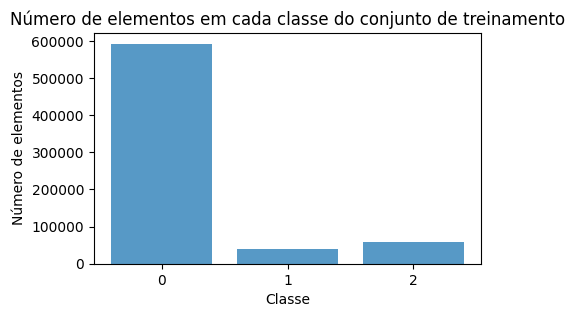

In [52]:
classes = y_train
cl = np.unique(classes)
ncl = np.zeros(len(cl))

for i in np.arange(0, len(cl)):
    a = classes == cl[i]
    ncl[i] = len(classes[a])

numbers = np.arange(0, len(cl))
plt.figure(figsize=(5, 3))
plt.bar(numbers, ncl,  alpha=.75)
plt.xticks(numbers, cl)
plt.title('Número de elementos em cada classe do conjunto de treinamento')
plt.xlabel('Classe')
plt.ylabel('Número de elementos')
plt.show(True)


- **0:** `em_risco`
- **1:** `em_forma`
- **2:** `não saudável`

Vemos que o conjunto de treinamento está desbalanceado, o que significa que algumas classes possuem muito mais observações do que outras. Isso pode fazer com que o modelo tenha uma tendência a prever a classe majoritária, apresentando um desempenho ruim na identificação das classes minoritárias. Quando formos aplicar o modelo de ML vamos levar isso em consideração.

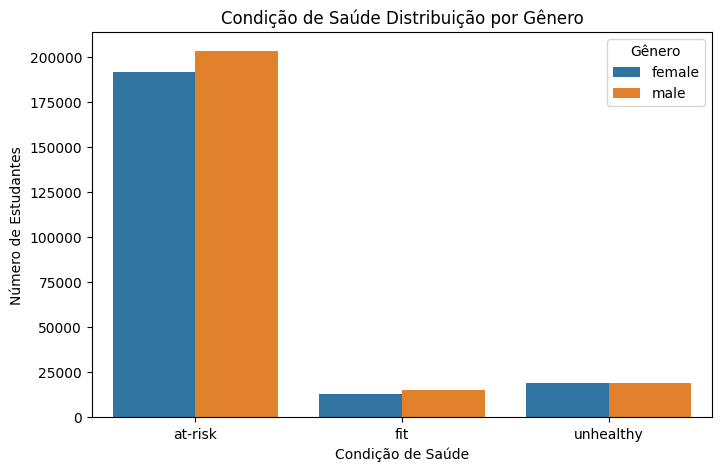

In [55]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Carregar os dados originais para obter a coluna 'gender' original
df_temp = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Predicting Student Health Risk/train.csv', usecols=['health_condition', 'gender'])

# Remover categoria "other" e valores nulos
train_gender = df_temp[(df_temp['gender'] != 'other') & (df_temp['gender'].notnull())]

plt.figure(figsize=(8,5))

sns.countplot(
    x='health_condition',
    hue='gender',
    data=train_gender,
    order=['at-risk', 'fit', 'unhealthy']
)

plt.title('Condição de Saúde Distribuição por Gênero')
plt.xlabel('Condição de Saúde')
plt.ylabel('Número de Estudantes')
plt.legend(title='Gênero')

plt.show()

### Matriz de Correlação

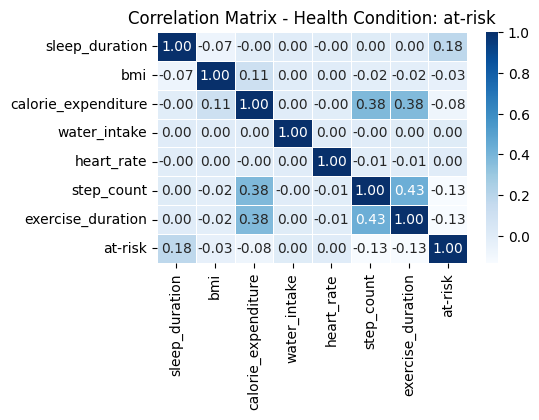

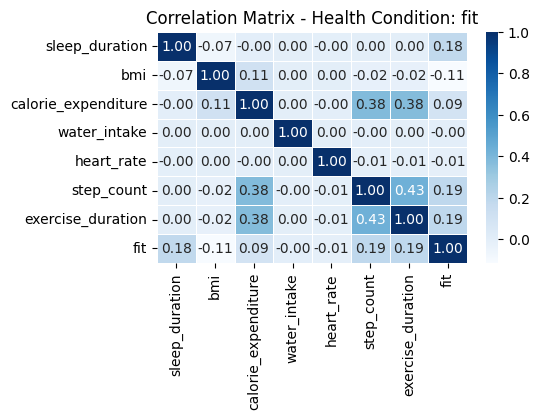

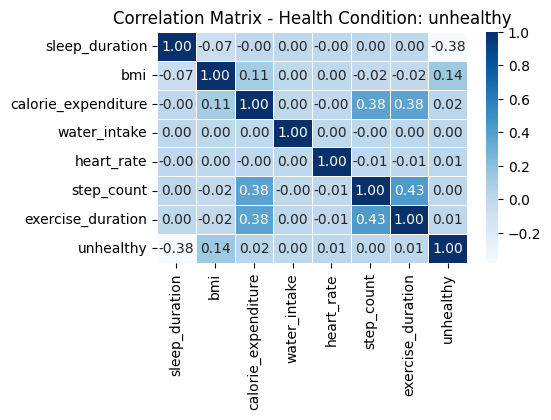

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Criar cópia do dataframe
train_corr = train.copy()


# Criar variáveis binárias das classes
train_corr['at-risk'] = (
    train_corr['health_condition'] == 'at-risk'
).astype(int)


train_corr['fit'] = (
    train_corr['health_condition'] == 'fit'
).astype(int)


train_corr['unhealthy'] = (
    train_corr['health_condition'] == 'unhealthy'
).astype(int)


# Variáveis numéricas de interesse
features = [
    'sleep_duration',
    'bmi',
    'calorie_expenditure',
    'water_intake',
    'heart_rate',
    'step_count',
    'exercise_duration'
]


# Classes para gerar os gráficos
health_classes = ['at-risk', 'fit', 'unhealthy']


# Criar uma matriz para cada classe
for health_class in health_classes:

    selected_features = features + [health_class]

    corr = train_corr[selected_features].corr()


    plt.figure(figsize=(5, 3))

    sns.heatmap(
        corr,
        annot=True,
        fmt='.2f',
        cmap='Blues',
        linewidths=0.5
    )


    plt.title(
        f'Correlation Matrix - Health Condition: {health_class}'
    )

    plt.show()

###  Boxplot por condição de saúde

Agora, vamos comparar a distribuição da duração do sono entre as diferentes condições de saúde. Esse gráfico permite identificar possíveis diferenças entre as classes, além de observar a mediana, a dispersão dos dados e a presença de possíveis valores discrepantes (*outliers*).

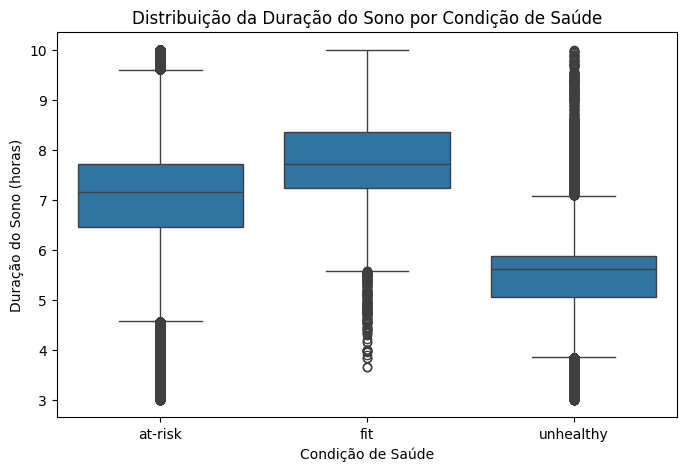

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=train_original, x="health_condition", y="sleep_duration", order=['at-risk', 'fit', 'unhealthy'])
plt.title("Distribuição da Duração do Sono por Condição de Saúde")
plt.xlabel("Condição de Saúde")
plt.ylabel("Duração do Sono (horas)")
plt.show()

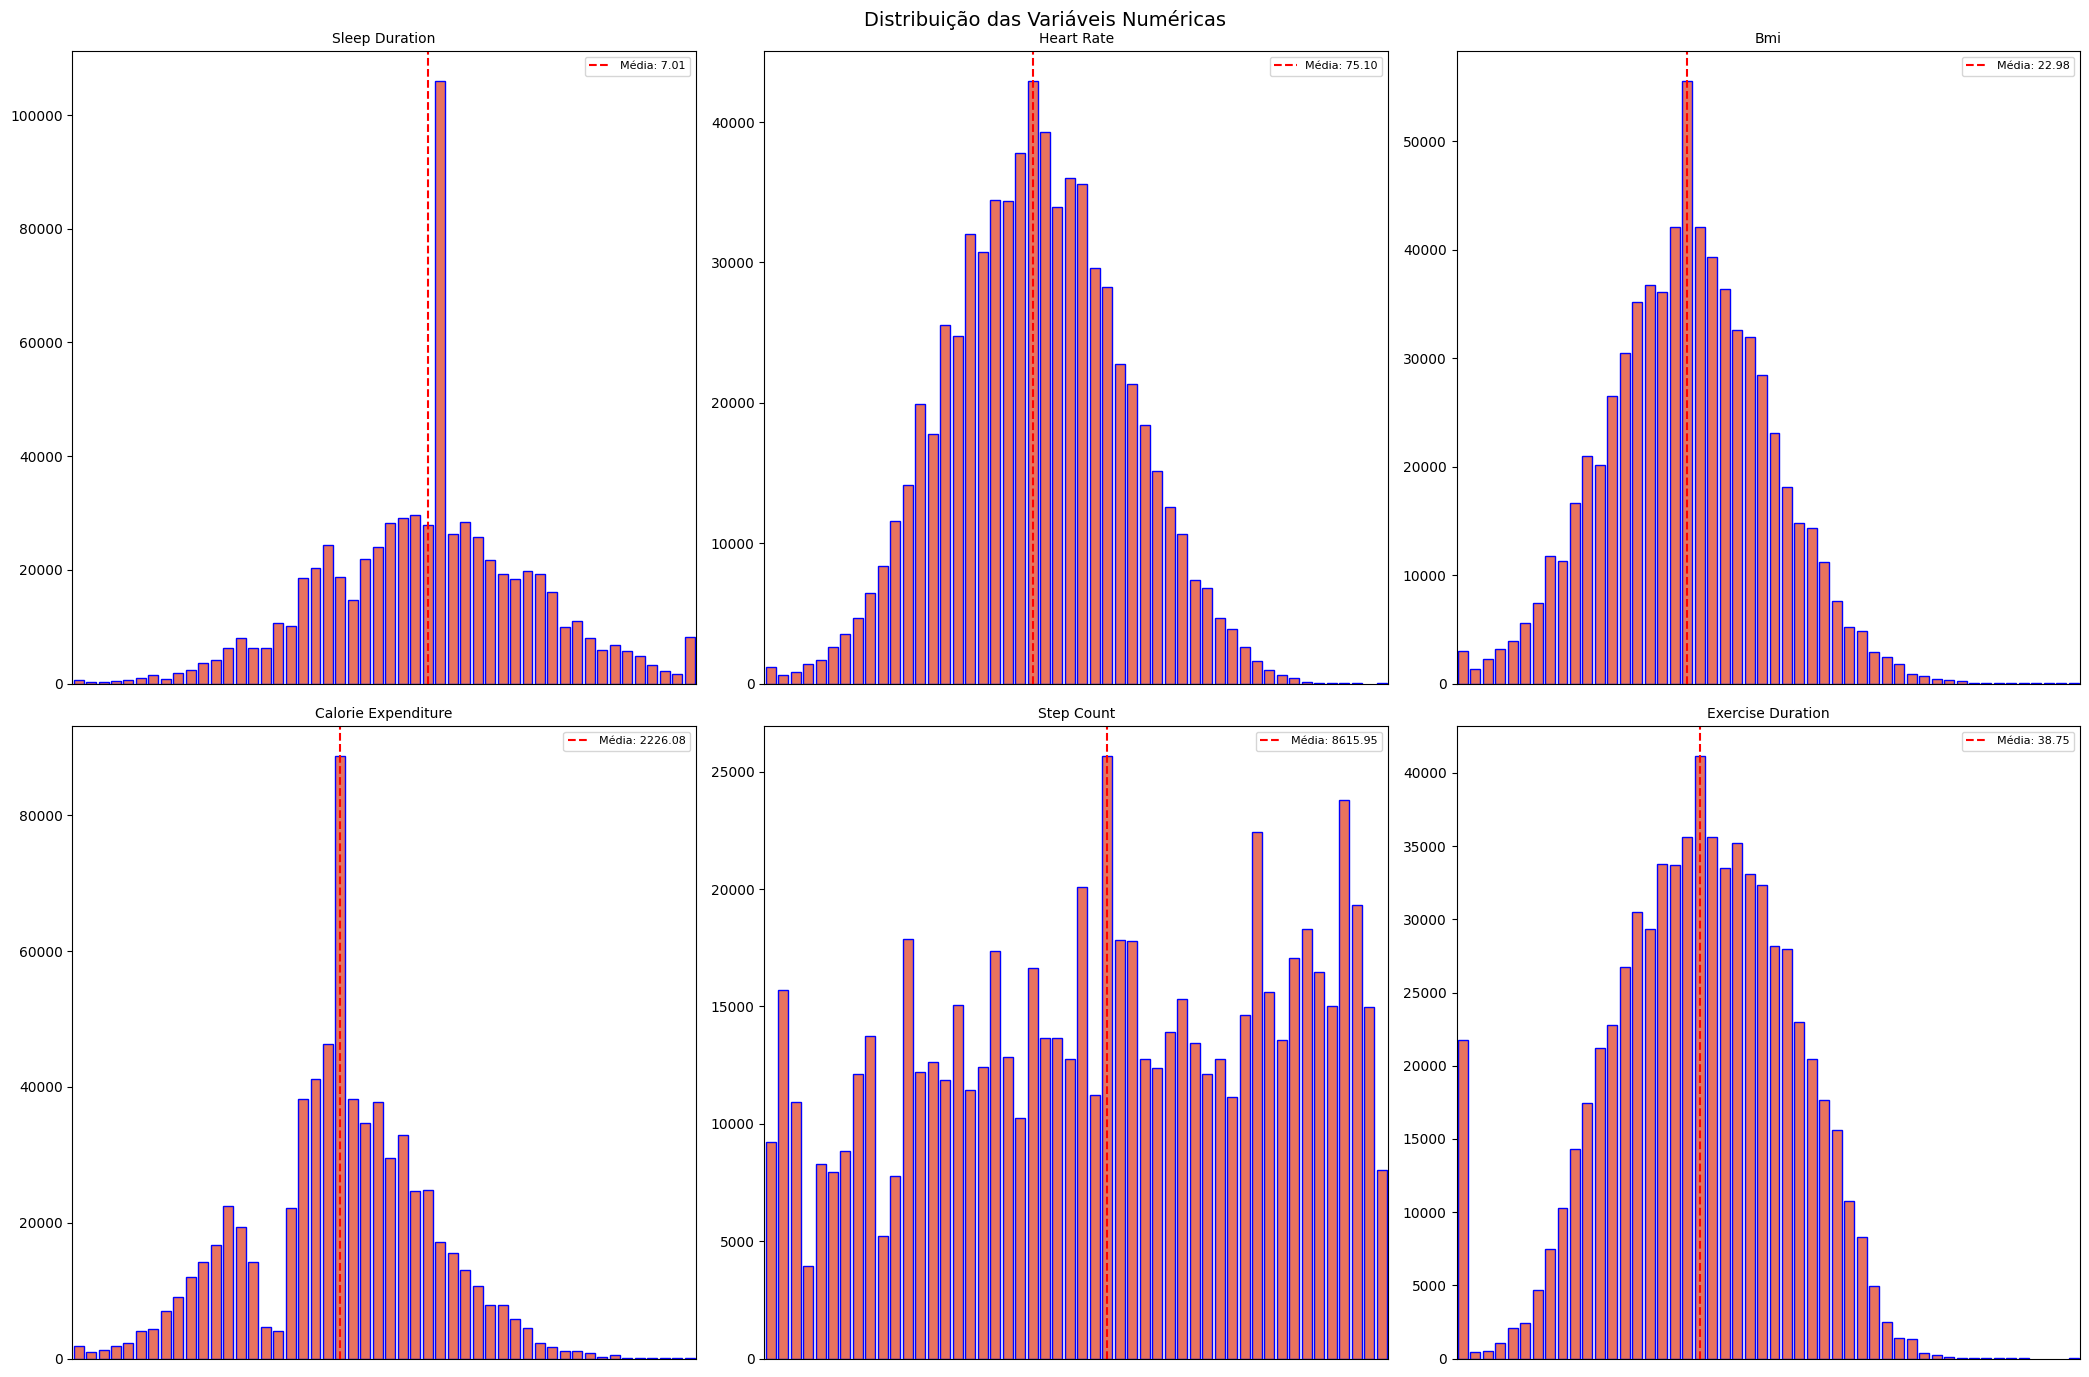

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

def plot_distribuicao(ax, data, coluna, n_intervalos=50):

    # Calculando os intervalos
    minimo = data[coluna].min()
    maximo = data[coluna].max()

    bins = np.linspace(minimo, maximo, n_intervalos + 1)

    grupos = pd.cut(data[coluna], bins=bins, include_lowest=True)

    # Média geral
    media = data[coluna].mean()

    sns.countplot(
        x=grupos,
        color='tomato',
        edgecolor='blue',
        ax=ax
    )

    # Posição da média no gráfico
    pos_media = np.searchsorted(bins, media, side='right') - 1

    ax.axvline(
        x=pos_media,
        color='red',
        linestyle='--',
        linewidth=1.5,
        label=f'Média: {media:.2f}'
    )

    ax.set_title(coluna.replace('_', ' ').title(), fontsize=10)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_xticks([])
    ax.legend(fontsize=8)


# Variáveis numéricas
variaveis = [
    'sleep_duration',
    'heart_rate',
    'bmi',
    'calorie_expenditure',
    'step_count',
    'exercise_duration'
]

fig, axes = plt.subplots(2, 3, figsize=(21, 14))

for ax, coluna in zip(axes.flatten(), variaveis):
    plot_distribuicao(ax, train, coluna)

plt.suptitle('Distribuição das Variáveis Numéricas', fontsize=14)
plt.tight_layout()
plt.show()

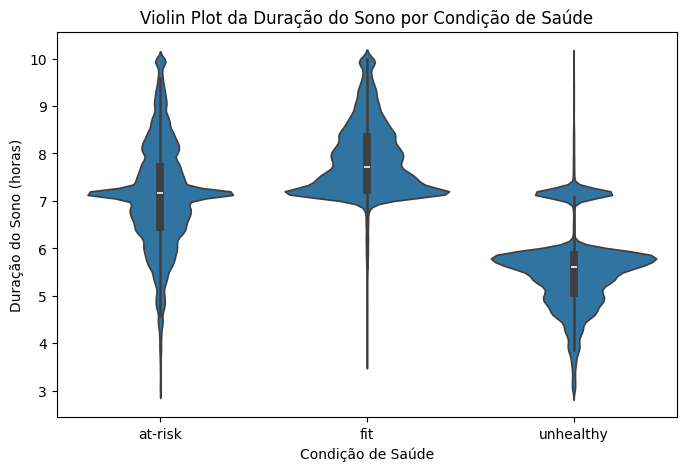

In [ ]:
plt.figure(figsize=(8, 5))
sns.violinplot(data=train_original, x="health_condition", y="sleep_duration", order=['at-risk', 'fit', 'unhealthy'])
plt.xlabel("Condição de Saúde")
plt.ylabel("Duração do Sono (horas)")
plt.title("Violin Plot da Duração do Sono por Condição de Saúde")
plt.show()




Podemos realizar um resumo estatístico das variáveis, analisando medidas como média, mediana, desvio padrão, valores mínimo e máximo e quartis. Essa análise permite compreender melhor a distribuição dos dados, identificar possíveis discrepâncias e obter uma visão geral das características do conjunto de dados.

In [ ]:
train_original.groupby("health_condition").describe().T

health_condition                 at-risk           fit     unhealthy
sleep_duration      count  592561.000000  39803.000000  57724.000000
                    mean        7.094572      7.867382      5.562990
                    std         1.078741      0.774564      0.845270
                    min         3.000000      3.660000      3.000000
                    25%         6.450000      7.240000      5.060000
                    50%         7.160000      7.710000      5.610000
                    75%         7.710000      8.350000      5.870000
                    max        10.000000     10.000000      9.990000
heart_rate          count  592561.000000  39803.000000  57724.000000
                    mean       75.100487     74.806927     75.255294
                    std         8.145376      8.177552      7.914273
                    min        50.000000     50.000000     50.000000
                    25%        69.500000     69.200000     69.900000
                    50%        75.096504     74.600000     75.096504
                    75%        80.600000     80.400000     80.500000
                    max       107.700000    106.700000    102.500000
bmi                 count  592561.000000  39803.000000  57724.000000
                    mean       22.950327     21.861635     24.114638
                    std         2.397056      2.502049      2.586875
                    min        16.010000     16.000000     19.850000
                    25%        21.350000     20.290000     22.140000
                    50%        22.984925     22.350000     23.670000
                    75%        24.590000     23.740000     25.690000
                    max        30.830000     26.000000     34.820000
calorie_expenditure count  592561.000000  39803.000000  57724.000000
                    mean     2215.796147   2353.372618   2243.933666
                    std       334.071387    302.370029    334.724310
                    min      1200.000000   1202.000000   1201.000000
                    25%      2061.000000   2163.000000   2081.000000
                    50%      2226.084931   2310.000000   2227.000000
                    75%      2431.000000   2560.000000   2452.000000
                    max      3580.000000   3453.000000   3553.000000
step_count          count  592561.000000  39803.000000  57724.000000
                    mean     8410.942331  11590.833298   8669.175250
                    std      3878.057052   2663.021134   3879.845719
                    min      1002.000000   1046.000000   1004.000000
                    25%      5263.000000   9462.000000   5579.000000
                    50%      8615.953050  12258.000000   8792.000000
                    75%     11893.000000  13974.000000  12107.000000
                    max     14999.000000  14999.000000  14999.000000
exercise_duration   count  592561.000000  39803.000000  57724.000000
                    mean       37.972754     49.924090     39.041175
                    std        14.604423     10.549215     14.615021
                    min         0.000000      0.000000      0.000000
                    25%        28.500000     41.900000     29.600000
                    50%        38.751456     50.400000     39.500000
                    75%        48.500000     58.200000     49.500000
                    max        99.800000     88.300000     90.100000
water_intake        count  592561.000000  39803.000000  57724.000000
                    mean        2.189093      2.179770      2.188934
                    std         0.500929      0.513439      0.503649
                    min         0.500000      0.500000      0.500000
                    25%         1.870000      1.840000      1.870000
                    50%         2.188542      2.188542      2.188542
                    75%         2.470000      2.470000      2.480000
                    max         4.720000      4.670000      4.720000

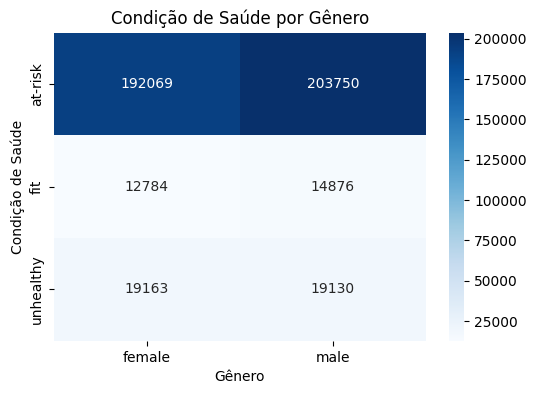

gender            female    male
health_condition                
at-risk           192069  203750
fit                12784   14876
unhealthy          19163   19130


In [56]:
import seaborn as sns
import matplotlib.pyplot as plt

# Usar df_temp que contém as colunas 'gender' e 'health_condition' originais em texto
train_gender = df_temp[
    (df_temp['gender'] != 'other') & (df_temp['gender'].notnull())
]

# Criar tabela de frequência
health_gender = (
    train_gender
    .groupby(['health_condition', 'gender'])
    .size()
    .unstack()
)

# Garantir a ordem das classes
health_gender = health_gender.reindex(
    ['at-risk', 'fit', 'unhealthy']
)

# Plot heatmap
plt.figure(figsize=(6,4))

sns.heatmap(
    health_gender,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Condição de Saúde por Gênero')
plt.xlabel('Gênero')
plt.ylabel('Condição de Saúde')

plt.show()

# Mostrar tabela
print(health_gender)

### Treinamento dos modelos

Agora, vamos treinar três algoritmos de classificação: Decision Tree e Naive Bayes. O objetivo é comparar o desempenho de diferentes abordagens de aprendizado de máquina na previsão das condições de saúde (`health_condition`).

Cada algoritmo possui características distintas, permitindo avaliar qual apresenta melhores resultados para o problema proposto. Posteriormente, compararemos as métricas de desempenho, como Accuracy, Precision, Recall e F1-Score, para identificar o modelo mais adequado.

Agora, vamos realizar a normalização dos atributos numéricos, colocando-os em uma escala comum. Esse procedimento evita que variáveis com magnitudes maiores tenham influência desproporcional no treinamento, contribuindo para o desempenho de determinados algoritmos de aprendizado de máquina.

_____________________________________________________________________________
### Modelo: Decision Tree

Vamos utilizar a **validação cruzada (*Cross-Validation*)** para encontrar a melhor combinação de hiperparâmetros para modelo. Após identificar a configuração que apresenta o melhor desempenho, treinaremos o modelo com os dados de treinamento e realizaremos as previsões no conjunto de teste.

Por fim, avaliaremos o desempenho do modelo por meio de diferentes métricas, como **Accuracy, Precision, Recall e F1-Score**, além da matriz de confusão, permitindo uma análise mais completa da capacidade de classificação do algoritmo.

In [18]:
from sklearn.tree import DecisionTreeClassifier


# modelo
tree = DecisionTreeClassifier(random_state=42)

# grade de hiperparâmetros
param_grid = {
    # Medida usada para avaliar a qualidade das divisões
    "criterion": ["gini", "entropy"],
    # Profundidade máxima da árvore
    "max_depth": [None, 10, 20, 25],
    # Número mínimo de observações para dividir um nó
    "min_samples_split": [2, 5],
    # Número mínimo de observações em cada folha
    "min_samples_leaf": [1, 2],
    # Número de atributos considerados em cada divisão
    "max_features": [None, "sqrt"],
}

In [19]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV

# Validação cruzada estratificada pois o conjunto de treino está desbalanceado
cv = StratifiedKFold(
    n_splits=2,
    shuffle=True,
    random_state=42
)
# define o GridSearchCV
grid_search = GridSearchCV(
    estimator=tree,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    return_train_score=True,
    refit=True
)
# Faz o ajuste aos dados
grid_search.fit(X_train, y_train)

Fitting 2 folds for each of 64 candidates, totalling 128 fits


GridSearchCV(cv=StratifiedKFold(n_splits=2, random_state=42, shuffle=True),
             estimator=DecisionTreeClassifier(random_state=42), n_jobs=-1,
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [None, 10, 20, 25],
                         'max_features': [None, 'sqrt'],
                         'min_samples_leaf': [1, 2],
                         'min_samples_split': [2, 5]},
             return_train_score=True, scoring='accuracy', verbose=1)

In [21]:
print("\nMelhores hiperparâmetros:")
print(grid_search.best_params_)
print("\nMelhor acurácia média na validação cruzada:",f"{grid_search.best_score_:.4f}")

best_tree = grid_search.best_estimator_


Melhores hiperparâmetros:
{'criterion': 'entropy', 'max_depth': 10, 'max_features': None, 'min_samples_leaf': 2, 'min_samples_split': 5}

Melhor acurácia média na validação cruzada: 0.9641


In [23]:
from sklearn.metrics import accuracy_score


y_train_pred = best_tree.predict(X_train)
y_pred = best_tree.predict(X_test)

# Volta para os nomes das classes
y_pred = le.inverse_transform(y_pred)

accuracy_train = accuracy_score(y_train, y_train_pred)
print(f"Acurácia no conjunto de treinamento: {accuracy_train:.4f}")

# Arquivo de submissão
submission = pd.DataFrame({
    'id': Id_test,
    'health_condition': y_pred
})

submission.to_csv('submission_decision_tree.csv', index=False)


Acurácia no conjunto de treinamento: 0.9651


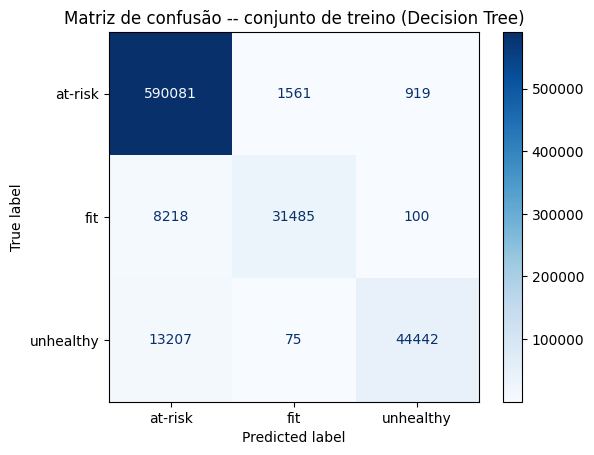

In [27]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calcula a matriz de confusão: linhas = classe real, colunas = classe prevista.
matriz_confusao = confusion_matrix(y_train, y_train_pred)

# ConfusionMatrixDisplay monta a visualizacao a partir da matriz calculada acima.
disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_confusao,
    display_labels=le.classes_
)

disp.plot(cmap="Blues", values_format="d")  # values_format="d" mostra os valores como inteiros
plt.title("Matriz de confusão -- conjunto de treino (Decision Tree)")
plt.show()

In [30]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score
)

print(classification_report(y_train, y_train_pred))

print("Acurácia Balanceada:",
      balanced_accuracy_score(y_train, y_train_pred))



              precision    recall  f1-score   support

           0       0.96      1.00      0.98    592561
           1       0.95      0.79      0.86     39803
           2       0.98      0.77      0.86     57724

    accuracy                           0.97    690088
   macro avg       0.96      0.85      0.90    690088
weighted avg       0.97      0.97      0.96    690088

Acurácia Balanceada: 0.8522468732292205


_____________________________________________________________________________
### Modelo: Naive-Bayes

O Naive Bayes é um algoritmo de classificação supervisionada baseado no Teorema de Bayes da teoria das probabilidades. Ele é amplamente reconhecido por ser simples, extremamente rápido e eficiente, sendo muito utilizado em problemas de classificação de texto (como filtros de spam), análise de sentimentos e diagnósticos médicos.

In [31]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

# Treina o modelo
gnb = GaussianNB()
gnb.fit(X_train, y_train)

# Faz previsões
y_pred = gnb.predict(X_test)

# Volta para os nomes das classes
y_pred = le.inverse_transform(y_pred)

# Acurácia no conjunto de treino
y_pred_train = gnb.predict(X_train)
accuracy_train = accuracy_score(y_train, y_pred_train)
print(f"Acurácia no conjunto de treino: {accuracy_train:.4f}")

# Arquivo de submissão
submission = pd.DataFrame({
    'id': Id_test,
    'health_condition': y_pred
})

submission.to_csv('submission_Naive_Bayes.csv', index=False)


Acurácia no conjunto de treino: 0.8982


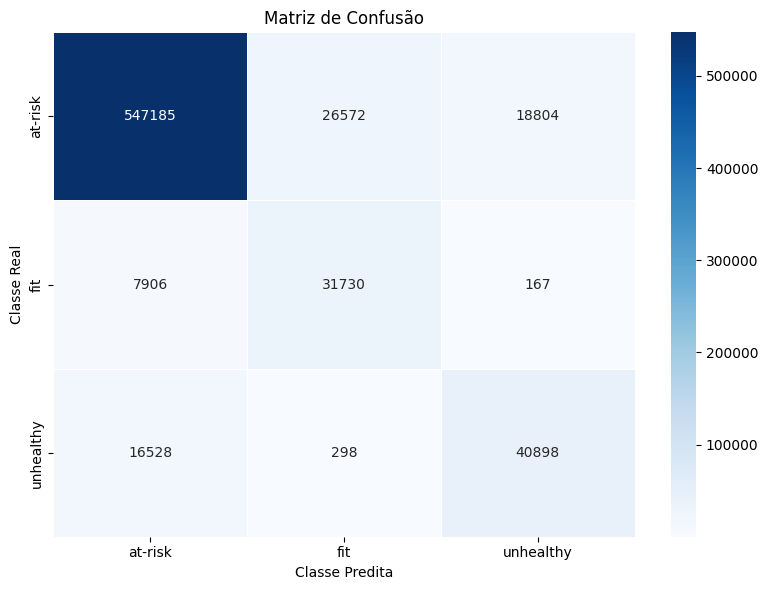

In [33]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Calcula a matriz de confusão
cm = confusion_matrix(y_train, y_pred_train)

# Desenha a matriz
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=0.5,
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.xlabel('Classe Predita')
plt.ylabel('Classe Real')
plt.title('Matriz de Confusão')

plt.tight_layout()
plt.show()

In [35]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score
)

print(classification_report(y_train, y_pred_train))

print("Acurácia Balanceada:",
      balanced_accuracy_score(y_train, y_pred_train))



              precision    recall  f1-score   support

           0       0.96      0.92      0.94    592561
           1       0.54      0.80      0.64     39803
           2       0.68      0.71      0.70     57724

    accuracy                           0.90    690088
   macro avg       0.73      0.81      0.76    690088
weighted avg       0.91      0.90      0.90    690088

Acurácia Balanceada: 0.8097031561986401


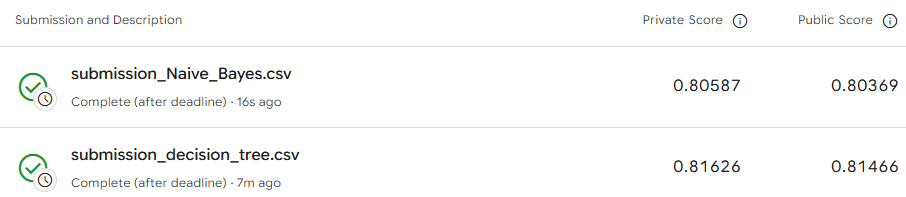




Resultados obtidos ao submeter o arquivo predito no Kaggle.